In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("data2.csv")
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
df.fillna(0, inplace=True)

In [3]:
X = df.drop(columns=["StudentId", "PlacementStatus"])
y = df["PlacementStatus"]
encoder = LabelEncoder()
X["Internship"] = encoder.fit_transform(X["Internship"])
X["Hackathon"] = encoder.fit_transform(X["Hackathon"])

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.30, random_state=42)

In [6]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion="entropy",
    random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(criterion='entropy', random_state=42)

In [7]:
dt_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [10]:
rf_pred = rf_model.predict(X_test)
dt_pred = dt_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
dt_accuracy = accuracy_score(y_test, dt_pred)
print(f"{rf_accuracy * 100:.2f}%")
print(f"{dt_accuracy * 100:.2f}%")

93.60%
91.73%


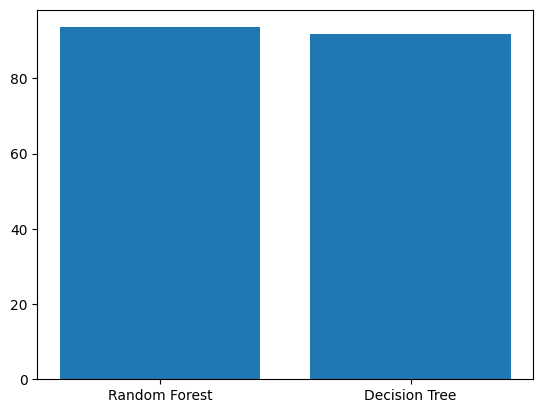

In [9]:
models = ["Random Forest", "Decision Tree"]
accuracy = [rf_accuracy * 100, dt_accuracy * 100]
plt.bar(models, accuracy)
plt.show()

In [11]:
if rf_accuracy > dt_accuracy:
  best_model = rf_model
else:
  best_model = dt_model

In [12]:
joblib.dump(best_model, "best_model.pkl")
loaded_model = joblib.load("best_model.pkl")

In [17]:
cgpa = float(input("Enter CGPA: "))
major_projects = int(input("Enter Number of Major Projects: "))
workshops = int(input("Enter Number of Workshops/Certifications: "))
mini_projects = int(input("Enter Number of Mini Projects: "))
skills = int(input("Enter Skills Rating (0-10): "))
communication = float(input("Enter Communication Skill Rating (0-5): "))
internship = int(input("Enter Internship (0 = No, 1 = Yes): "))
hackathon = int(input("Enter Hackathon (0 = No, 1 = Yes): "))
percentage_12 = float(input("Enter 12th Percentage: "))
percentage_10 = float(input("Enter 10th Percentage: "))
backlogs = int(input("Enter Number of Backlogs: "))


new_student = pd.DataFrame([{
    "CGPA": cgpa,
    "Major Projects": major_projects,
    "Workshops/Certificatios": workshops,
    "Mini Projects": mini_projects,
    "Skills": skills,
    "Communication Skill Rating": communication,
    "Internship": internship,
    "Hackathon": hackathon,
    "12th Percentage": percentage_12,
    "10th Percentage": percentage_10,
    "backlogs": backlogs
}])

prediction = loaded_model.predict(new_student)
print("Prediction :", prediction[0])

if prediction[0] == "Placed":
  print("Student is Placed")
else:
  print("Student is Not Placed")



Enter CGPA: 7.5
Enter Number of Major Projects: 2
Enter Number of Workshops/Certifications: 2
Enter Number of Mini Projects: 3
Enter Skills Rating (0-10): 8
Enter Communication Skill Rating (0-5): 4.4
Enter Internship (0 = No, 1 = Yes): 1
Enter Hackathon (0 = No, 1 = Yes): 1
Enter 12th Percentage: 78
Enter 10th Percentage: 80
Enter Number of Backlogs: 0
Prediction : Placed
Student is Placed
